# Pull Request Complexity and Merge Behavior Analysis

This notebook analyzes all pull requests from **~66 million** enterprise repositories. Before we calcuate PR code complexity we must first understand the dataset the features and how they are related.

### 1. Import Dependencies

This section loads the Python libraries used for data processing, visualization, and file management. The display and plotting settings are configured to make tabular summaries and figures easier to review.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

import sys
from pathlib import Path
sys.path.insert(0, "/Users/syd-kiwi/Code/bam/notebooks")

from sqlalchemy import create_engine
import warnings
warnings.filterwarnings('ignore')
import math

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', 100)

sns.set_theme(style='whitegrid', context='notebook', palette='husl')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

### 2. Load Dataset Versions

This section loads the enterpirse pull requests The PRs come from **delta.data_science.code_complexity_current** We only consider PRs June 1st through June 8th and PRs that have 28 pulls per repo. 

In [ ]:
files = [
    "../data/code_complexity_march_month.csv",
    "../data/code_complexity_april_month.csv",
    "../data/code_complexity_may_month.csv"
]

df = pd.concat([pd.read_csv(file) for file in files], ignore_index=True)

df.shape



(66707531, 27)

In [12]:
df.head()

,month,week,merge_day,billable_owner_id,user_id,repository_id,pull_request_id,oid,had_copilot_seat,files_added,files_deleted,files_modified,files_touched,minutes_to_merge,lines_added_by_language,lines_deleted_by_language,languages_list,languages,lines_modified,config_lines_modified,code_lines_modified,is_code_pr,standardized_complexity_score,complexity_score,num_reviewers,num_review_comments,day
0,2026-03-01,2026-03-23,2026-03-24,1524,126273433,486541448,3439374303,0cdae97f96b6757197f46253870468297211f3d5,False,0,0,4,4,3,{'Apex': 281},{'Apex': 133},['Apex'],1,414,0,414,True,-34.614281,61.0,0,0,2026-07-06
1,2026-03-01,2026-03-30,2026-03-30,22334,226638152,1011007863,3466378920,f3b96f4b74a399aa9839de30e06a611c481060cc,True,1,0,2,3,101,"{'TSX': 2, 'Markdown': 5}",{'TSX': 2},"['Markdown', 'TSX']",2,9,5,4,False,9.186370,68.0,1,0,2026-07-06
2,2026-03-01,2026-03-02,2026-03-05,510402,146705701,833007511,3359169207,faa0a852de403b5cef56e628197028f0b6c90179,True,7,17,298,322,10,"{'JSON': 1287, 'Text': 7, 'PHP': 113, 'Gettext Catalog': 3898, 'SVG': 13, 'Ignore List': 1}","{'Gettext Catalog': 1016, 'JSON': 3401, 'PHP': 32}","['Gettext Catalog', 'Ignore List', 'JSON', 'PHP', 'SVG', 'Text']",6,9768,4696,5072,True,444.773185,99.0,1,0,2026-07-06
3,2026-03-01,2026-03-30,2026-03-30,7592,155647353,854596087,3465738079,79a421893cb94314d79a0bf0a3f29ed54af6410b,False,0,0,2,2,25,{'YAML': 31},{'YAML': 31},['YAML'],1,62,62,0,False,-41.440251,48.0,1,0,2026-07-06
4,2026-03-01,2026-03-16,2026-03-18,13473,141091748,1084054025,3415924870,6ff0e1386a825848e0f2d2f1d5bbb4658ec1ae37,True,0,0,2,2,0,{'TypeScript': 15},{'TypeScript': 2},['TypeScript'],1,17,0,17,True,-42.273576,37.0,0,0,2026-07-06


### 3. Dataset

This section prepares the combined pull request data for downstream analysis. The notebook first concatenates the monthly CSV files into a single dataframe, then standardizes the core PR fields and derived complexity measures used later in the analysis.

#### 3a. Clean and standardize the dataset

The code normalizes text columns, fills missing values where needed, and creates consistent PR-level features such as:

- title and body cleaning for downstream NLP
- language detection and filtering to English-only PRs
- size and complexity features such as lines modified, files touched, and a composite complexity score
- user identifiers and required PR metadata columns if they are missing

This step makes the dataset easier to compare across repositories and helps ensure the text analysis is based on a consistent, cleaned corpus.

#### 3b. Check for missing values and duplicates

After preprocessing, the notebook validates the dataset quality by:

- reporting missing values per column
- checking whether pull request records are unique by repository and PR ID
- identifying duplicate PR rows before any later modeling or aggregation

This ensures the analysis is based on a clean, de-duplicated PR dataset with a stable record key.

In [5]:
import re
import numpy as np
import pandas as pd

from langdetect import DetectorFactory, LangDetectException, detect
from tqdm import tqdm

# Enable tqdm progress bars for pandas
tqdm.pandas()

DetectorFactory.seed = 42

TITLE_COL = "title"
BODY_COL = "body"


# ============================================================
# SET UP DATAFRAME
# ============================================================

missing_text_cols = [
    col for col in [TITLE_COL, BODY_COL]
    if col not in df.columns
]

if missing_text_cols:
    raise ValueError(f"Missing text columns: {missing_text_cols}")


# ============================================================
# STOPWORDS
# ============================================================

DEFAULT_STOPWORDS = {
    "a", "an", "and", "are", "as", "at", "be", "by", "for", "from", "has", "have",
    "in", "into", "is", "it", "its", "of", "on", "or", "that", "the", "this", "to",
    "was", "were", "will", "with", "without", "we", "you", "your", "our", "their",
    "pr", "pull", "request", "merge", "merged", "branch", "commit", "commits", "github",
    "com", "http", "https", "www", "url", "urls", "href", "hrefs", "id", "ids", "file",
    "files", "code", "change", "changes", "update", "updates", "updated", "add", "added",
    "remove", "removed", "use", "using", "used", "new", "old", "make", "made", "set",
    "get", "also", "one", "two", "true", "false", "none", "null", "na", "n", "amp",
    "nbsp", "src", "lib", "app", "main", "test", "tests", "spec", "specs", "tmp", "var",
    "const", "let", "function", "class", "method", "api", "utils", "util", "service",
    "component", "module", "object", "data", "value", "values", "type", "types", "bot",
    "ref", "refs", "issue_ref", "ticket_ref",
}

EXTRA_STOPWORDS = set()

STOPWORDS = DEFAULT_STOPWORDS | EXTRA_STOPWORDS

NOISE_TOKEN_PARTS = ("bot",)


# ============================================================
# TEXT CLEANING FUNCTIONS
# ============================================================

def normalize_text(text):
    if pd.isna(text):
        return ""

    text = str(text)

    text = re.sub(
        r"```.*?```",
        " ",
        text,
        flags=re.DOTALL
    )

    text = re.sub(
        r"`[^`]+`",
        " ",
        text
    )

    text = re.sub(
        r"&nbsp;|\bnbsp\b",
        " ",
        text,
        flags=re.IGNORECASE
    )

    text = re.sub(
        r"https?://\S+",
        " URL ",
        text
    )

    text = re.sub(
        r"#[0-9]+",
        " ",
        text
    )

    text = re.sub(
        r"\b[A-Z][A-Z0-9]+-\d+\b",
        " ",
        text
    )

    text = (
        text
        .replace("_", " ")
        .replace("-", " ")
        .replace("/", " ")
    )

    text = re.sub(
        r"[^A-Za-z0-9#+. ]+",
        " ",
        text
    )

    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip().lower()


def tokenize(text, min_len=3):

    raw_terms = re.findall(
        r"[a-z][a-z0-9+#.]*",
        str(text).lower()
    )

    terms = [
        term.strip("#+.")
        for term in raw_terms
    ]

    return [
        term
        for term in terms
        if len(term) >= min_len
        and term not in STOPWORDS
        and not term.isdigit()
        and not any(
            noise_part in term
            for noise_part in NOISE_TOKEN_PARTS
        )
    ]


def clean_for_nlp(text):
    return " ".join(
        tokenize(
            normalize_text(text)
        )
    )


def detect_pr_language(row):

    text = f"{row[TITLE_COL]} {row[BODY_COL]}".strip()

    text = normalize_text(text)

    if len(text) < 20:
        return "unknown"

    try:
        return detect(text)

    except LangDetectException:
        return "unknown"


def word_count(text):

    text = "" if pd.isna(text) else str(text)

    return len(
        re.findall(
            r"\b\w+\b",
            text
        )
    )


def q90(values):

    values = pd.to_numeric(
        values,
        errors="coerce"
    ).dropna()

    return (
        values.quantile(0.90)
        if len(values)
        else np.nan
    )


# ============================================================
# NUMERIC COLUMNS
# ============================================================

numeric_cols = [
    "minutes_to_merge",
    "lines_added",
    "lines_deleted",
    "files_added",
    "files_deleted",
    "files_modified",
    "num_reviewers",
    "num_review_comments"
]

for col in numeric_cols:

    if col in df.columns:

        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )


# ============================================================
# PR SIZE / COMPLEXITY VARIABLES
# ============================================================

zero_series = pd.Series(
    0,
    index=df.index
)

lines_added = (
    df["lines_added"]
    if "lines_added" in df.columns
    else zero_series
)

lines_deleted = (
    df["lines_deleted"]
    if "lines_deleted" in df.columns
    else zero_series
)

files_added = (
    df["files_added"]
    if "files_added" in df.columns
    else zero_series
)

files_deleted = (
    df["files_deleted"]
    if "files_deleted" in df.columns
    else zero_series
)

files_modified = (
    df["files_modified"]
    if "files_modified" in df.columns
    else zero_series
)


if "lines_modified" not in df.columns:

    df["lines_modified"] = (
        lines_added.fillna(0)
        +
        lines_deleted.fillna(0)
    )


if "files_touched" not in df.columns:

    df["files_touched"] = (
        files_added.fillna(0)
        +
        files_deleted.fillna(0)
        +
        files_modified.fillna(0)
    )


if "complexity_score" not in df.columns:

    df["complexity_score"] = (
        df["lines_modified"]
        +
        (10 * df["files_touched"])
    )


# ============================================================
# REQUIRED COLUMNS
# ============================================================

if "user_id" not in df.columns:

    if "author_id" in df.columns:
        df["user_id"] = df["author_id"]

    else:
        df["user_id"] = np.arange(len(df))


for col in [
    "pull_request_id",
    "repository_id",
    "num_reviewers",
    "num_review_comments",
    "minutes_to_merge"
]:

    if col not in df.columns:
        df[col] = np.nan


# ============================================================
# BASIC TEXT CLEANING
# ============================================================

df[TITLE_COL] = (
    df[TITLE_COL]
    .fillna("")
    .astype(str)
)

df[BODY_COL] = (
    df[BODY_COL]
    .fillna("")
    .astype(str)
)


df["title_clean"] = (
    df[TITLE_COL]
    .str.strip()
)

df["body_clean"] = (
    df[BODY_COL]
    .str.strip()
)

df["title_lower"] = (
    df["title_clean"]
    .str.lower()
)

df["body_lower"] = (
    df["body_clean"]
    .str.lower()
)


# ============================================================
# LANGUAGE DETECTION
# ============================================================

print("Detecting PR languages...")

df["detected_language"] = df.progress_apply(
    detect_pr_language,
    axis=1
)


language_counts_before_filter = (
    df["detected_language"]
    .value_counts(dropna=False)
)


rows_before_language_filter = len(df)


df = (
    df[
        df["detected_language"].eq("en")
    ]
    .reset_index(drop=True)
)


rows_removed_non_english = (
    rows_before_language_filter
    -
    len(df)
)


# ============================================================
# NLP CLEANING
# ============================================================

print("\nCleaning PR titles...")

df["title_clean_nlp"] = (
    df[TITLE_COL]
    .progress_apply(clean_for_nlp)
)


print("\nCleaning PR bodies...")

df["body_clean_nlp"] = (
    df[BODY_COL]
    .progress_apply(clean_for_nlp)
)


df["combined_text_nlp"] = (
    df["title_clean_nlp"]
    +
    " "
    +
    df["body_clean_nlp"]
).str.strip()


# ============================================================
# WORD COUNTS
# ============================================================

print("\nCounting title words...")

df["title_word_count"] = (
    df["title_clean"]
    .progress_apply(word_count)
)


print("\nCounting body words...")

df["body_word_count"] = (
    df["body_clean"]
    .progress_apply(word_count)
)


# ============================================================
# TEXT FLAGS
# ============================================================

df["has_title"] = (
    df["title_word_count"] > 0
)

df["has_body"] = (
    df["body_word_count"] > 0
)

df["short_body"] = (
    df["body_word_count"] < 20
)


# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 60)

print(
    f"Rows before language filter: "
    f"{rows_before_language_filter:,}"
)

print(
    f"Rows after English-only filter: "
    f"{len(df):,}"
)

print(
    f"Rows removed as non-English or unknown: "
    f"{rows_removed_non_english:,}"
)

print("=" * 60)


display(
    language_counts_before_filter
    .head(20)
    .rename_axis("detected_language")
    .reset_index(name="pr_count")
)


display(
    df[
        [
            TITLE_COL,
            BODY_COL,
            "detected_language",
            "title_word_count",
            "body_word_count",
            "combined_text_nlp"
        ]
    ].head()
)

NameError: name 'df' is not defined

In [5]:
# Check missing values and duplicate data from combined_df only

df = df.copy()

missing_summary = pd.DataFrame({
    "Column": df.columns,
    "Missing_Count": df.isna().sum().values,
    "Missing_%": (df.isna().mean().values * 100).round(2),
    "Non_Missing_Count": df.notna().sum().values,
    "Total_Rows": len(df)
})

missing_summary = missing_summary.sort_values("Missing_%", ascending=False)

# Show only columns that actually have missing values
# missing_only = missing_summary[missing_summary["Missing_Count"] > 0]
# print("\n=== COLUMNS WITH MISSING VALUES ONLY ===")
# display(missing_only)

# -----------------------------
# Make sure each PR is unique
# -----------------------------
pr_key = ["repository_id", "pull_request_id"]

# Check that both columns exist
missing_key_cols = [col for col in pr_key if col not in df.columns]

if missing_key_cols:
    raise ValueError(f"Missing key columns: {missing_key_cols}")

print("=== BEFORE DEDUPLICATION ===")
print(f"Rows: {len(df):,}")
print(f"Unique repository_id + pull_request_id pairs: {df[pr_key].drop_duplicates().shape[0]:,}")

duplicate_pr_count = df.duplicated(subset=pr_key).sum()
print(f"Duplicate PR rows: {duplicate_pr_count:,}")

=== BEFORE DEDUPLICATION ===
Rows: 66,707,531
Unique repository_id + pull_request_id pairs: 66,707,531
Duplicate PR rows: 0


In [6]:
PLOT_OUTPUT_DIR = Path('dataset_plots')
PLOT_OUTPUT_DIR.mkdir(exist_ok=True)

def save_plot(fig, filename):
    path = PLOT_OUTPUT_DIR / filename
    plt.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print(f'Saved: {path}')
    plt.show()
    plt.close(fig)
    return path

### 4. Pull Requests per Repository

### Plot 1: Top Repositories based on PRs
This plot shows the number of unique pull requests associated with each repository.

Repository imbalance can affect later analysis. If most pull requests come from only a few repositories, then patterns in review complexity may reflect those repositories more than general pull request behavior.

The dataset contains 66,707,531 unique PRs across 341,716 unique repositories.
The average number of PRs per repository is 195.21.


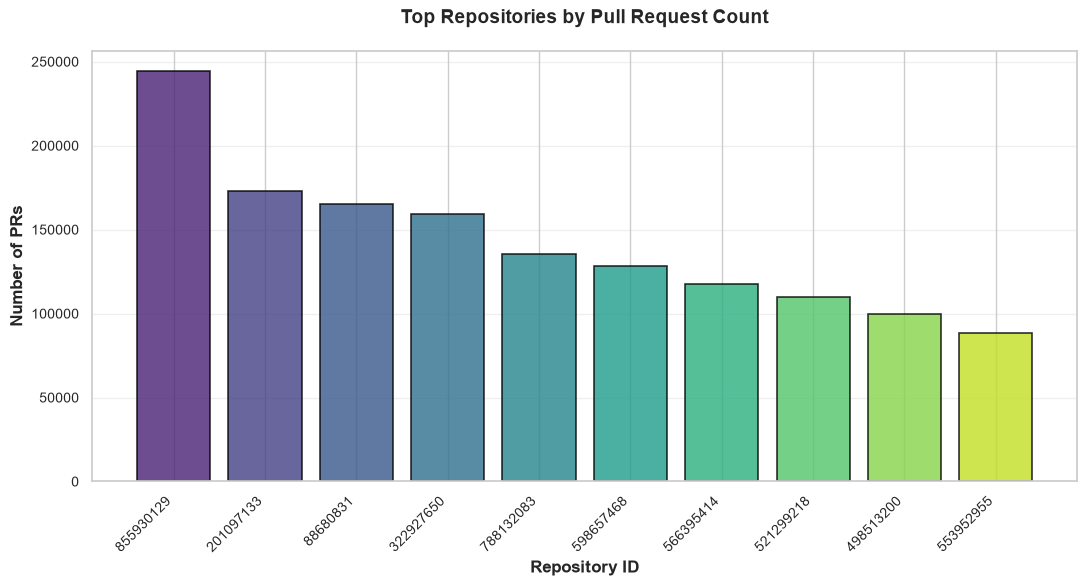

In [7]:
prs_per_repo = (
    df
    .groupby("repository_id")["pull_request_id"]
    .nunique()
    .reset_index()
)

prs_per_repo.columns = ["repository_id", "pr_count"]
prs_per_repo = prs_per_repo.sort_values("pr_count", ascending=False).head(10)

avg_prs_per_repo = (
    df
    .groupby("repository_id")["pull_request_id"]
    .nunique()
    .mean()
)

print(f"The dataset contains {df['pull_request_id'].nunique():,} unique PRs across {df['repository_id'].nunique():,} unique repositories.")
print(f"The average number of PRs per repository is {avg_prs_per_repo:.2f}.")

fig, ax = plt.subplots(figsize=(11, 6))
x_pos = range(len(prs_per_repo))
bars = ax.bar(
    x_pos,
    prs_per_repo["pr_count"],
    color=sns.color_palette("viridis", len(prs_per_repo)),
    edgecolor="black",
    linewidth=1.2,
    alpha=0.8
)

ax.set_xticks(x_pos)
ax.set_xticklabels(prs_per_repo["repository_id"], fontsize=10, rotation=45, ha="right")
ax.set_title("Top Repositories by Pull Request Count", fontsize=14, fontweight="bold", pad=20)
ax.set_xlabel("Repository ID", fontsize=12, fontweight="bold")
ax.set_ylabel("Number of PRs", fontsize=12, fontweight="bold")
ax.tick_params(axis="y", labelsize=10)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### Plot 2: Top Programming Languages

This chart reports the most frequent primary repository languages in the dataset. The distribution helps establish which language communities contribute most to the later comparisons of pull request size and merge behavior.

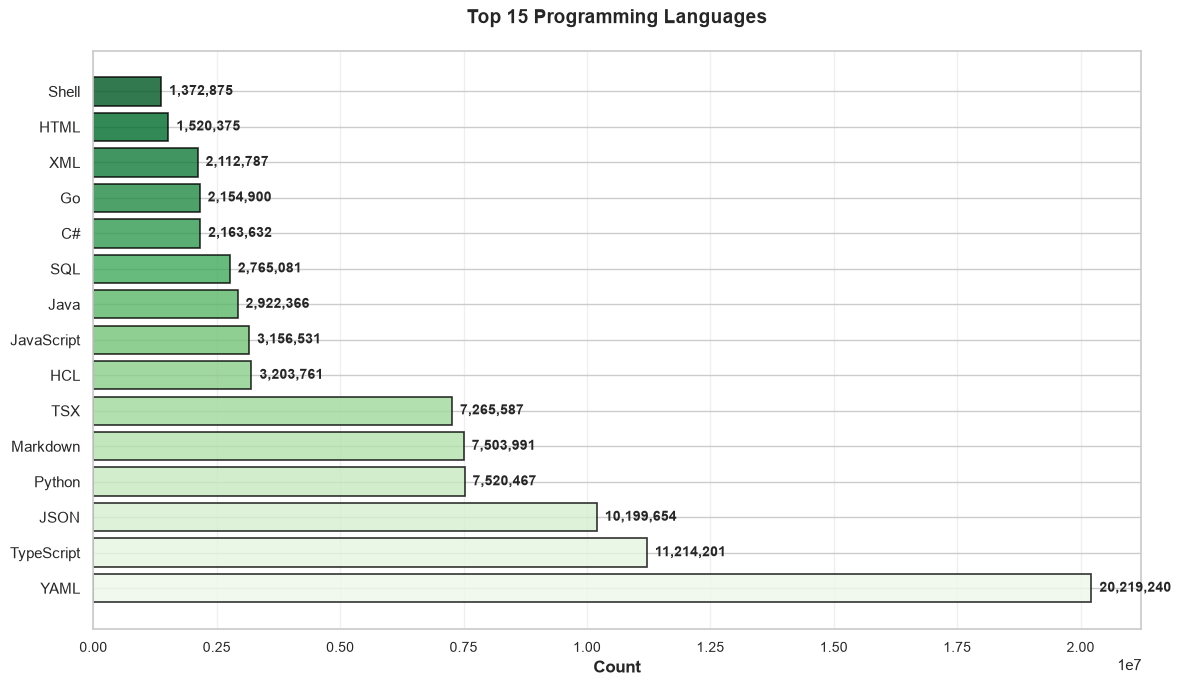

In [8]:
import os
import ast
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("dataset_plots", exist_ok=True)

df["languages_list"] = df["languages_list"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

lang_exploded = df.explode("languages_list")

if not lang_exploded.empty:
    fig, ax = plt.subplots(figsize=(12, 7))
    
    top_langs = lang_exploded["languages_list"].value_counts().head(15)
    
    x_pos = range(len(top_langs))
    bars = ax.barh(
        x_pos,
        top_langs.values,
        color=sns.color_palette("Greens", len(top_langs)),
        alpha=0.8,
        edgecolor="black",
        linewidth=1.2
    )
    
    ax.set_yticks(x_pos)
    ax.set_yticklabels(top_langs.index, fontsize=11)
    ax.set_xlabel("Count", fontsize=12, fontweight="bold")
    ax.set_title("Top 15 Programming Languages", fontsize=14, fontweight="bold", pad=20)
    
    for i, (bar, val) in enumerate(zip(bars, top_langs.values)):
        ax.text(val, i, f"  {int(val):,}", va="center", fontsize=10, fontweight="bold")
    
    ax.tick_params(axis="x", labelsize=10)
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)
    
    plt.tight_layout()
    plt.savefig("dataset_plots/02_primary_language_top15.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("No language column found. Available columns:", df.columns.tolist())

### Plot 5: Lines Added per Pull Request

This histogram shows the distribution of lines added per pull request. The visualization is limited to the 95th percentile to reduce the influence of extreme outliers and make the typical range of code-change size easier to interpret.

Lines added columns found: ['lines_modified', 'config_lines_modified', 'code_lines_modified']


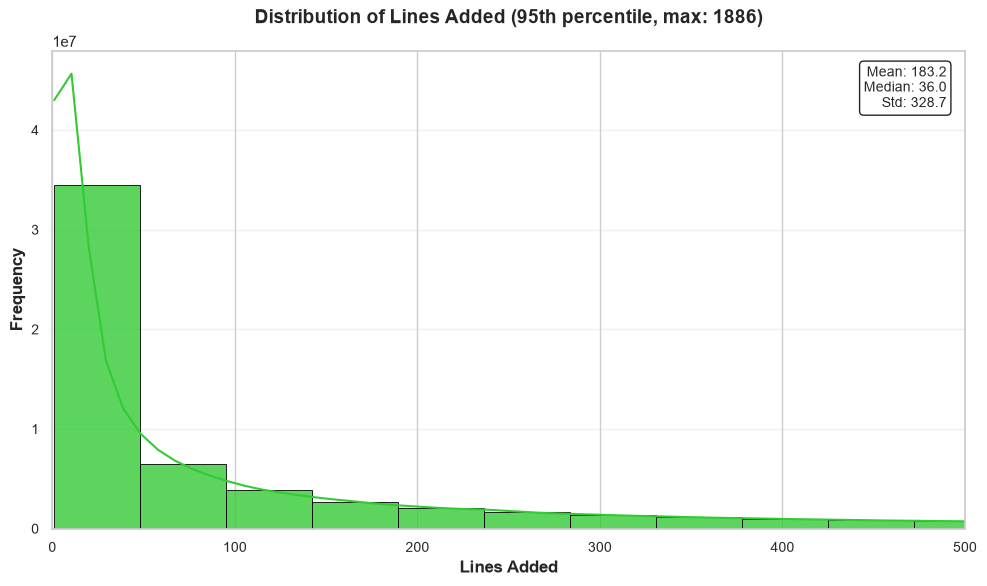

In [9]:
# Check for lines_added column
lines_cols = [col for col in df.columns if 'lines_modified' in col.lower() or 'lines modified' in col.lower()]
print(f'Lines added columns found: {lines_cols}')

if lines_cols:
    lines_col = lines_cols[0]
    
    # Convert to numeric
    df['lines_added_num'] = pd.to_numeric(df[lines_col], errors='coerce')
    
    # Remove outliers for better visualization (keep 95th percentile)
    lines_95 = df['lines_added_num'].quantile(0.95)
    lines_data = df[df['lines_added_num'] <= lines_95]['lines_added_num'].dropna()
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Create histogram with KDE
    sns.histplot(
        data=lines_data,
        bins=40,
        kde=True,
        ax=ax,
        color="#33CA35",
        alpha=0.8,
        edgecolor='black',
        linewidth=0.6
    )
    
    ax.set_xlabel('Lines Added', fontsize=12, fontweight='bold')
    ax.set_ylabel('Frequency', fontsize=12, fontweight='bold')
    ax.set_xlim(0, 500)
    ax.set_title(f'Distribution of Lines Added (95th percentile, max: {lines_95:.0f})', 
                 fontsize=14, fontweight='bold', pad=20)
    ax.tick_params(axis="both", labelsize=10)
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)
    
    # Add statistics
    stats_text = f"Mean: {lines_data.mean():.1f}\nMedian: {lines_data.median():.1f}\nStd: {lines_data.std():.1f}"
    ax.text(0.98, 0.97, stats_text, transform=ax.transAxes, ha='right', va='top',
            fontsize=10, bbox=dict(boxstyle='round', facecolor='white', edgecolor='black', alpha=0.85))
    
    plt.tight_layout()
    plt.savefig('dataset_plots/05_lines_added_distribution.png', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print('No lines_added column found. Available columns:', df.columns.tolist())

### Prior Findings on Median Pull Request Size

| Dataset / Project | Median PR Size |
|---|---:|
| Android / AMD | 44 lines |
| Apache | 25 lines |
| Linux | 32 lines |
| Chrome | 78 lines |
| Lucent | 263 lines |

Prior studies show substantial variation in median pull request size across software projects. In this reference set, Lucent reports the largest median pull request size, while Apache reports the smallest.

Lucent Technologies was the research branch of AT&T, so its results represent an industrial software context rather than an open-source community project.

### 5. Language-Based Analysis

This section compares pull request size and merge speed across the most common primary repository languages. The analysis focuses on the top 12 languages to keep the figures readable while preserving the dominant language groups in the dataset.

### Plot 6: Average Pull Request Size by Programming Language

This chart compares the average number of lines added per pull request by language. The labels include both the average size and the number of pull requests represented, which helps distinguish large-language groups from smaller samples.

In [10]:
# Plot 6: Average PR Size by Language

import os
import ast
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("dataset_plots", exist_ok=True)


# ------------------------------------------------------------
# Parse lines_added_by_language
# Example:
# "{'Python': 120, 'JavaScript': 50}"
# becomes:
# {'Python': 120, 'JavaScript': 50}
# ------------------------------------------------------------

def parse_language_dict(value):
    if isinstance(value, dict):
        return value
    
    if isinstance(value, str):
        try:
            parsed = ast.literal_eval(value)
            return parsed if isinstance(parsed, dict) else {}
        except (ValueError, SyntaxError):
            return {}
    
    return {}


df["language_lines"] = df["lines_added_by_language"].apply(parse_language_dict)


# ------------------------------------------------------------
# Convert each language dictionary into separate rows
#
# Example:
# {'Python': 120, 'JavaScript': 50}
#
# becomes:
#
# Python       120
# JavaScript    50
# ------------------------------------------------------------

language_df = (
    df["language_lines"]
    .apply(pd.Series)
    .stack()
    .reset_index()
)

language_df.columns = ["pr_index", "language", "lines_added"]

language_df["lines_added"] = pd.to_numeric(
    language_df["lines_added"],
    errors="coerce"
)

language_df = language_df.dropna(subset=["lines_added"])


# ------------------------------------------------------------
# Find the 12 languages appearing in the most PRs
# ------------------------------------------------------------

top_languages = (
    language_df["language"]
    .value_counts()
    .head(12)
    .index
)

plot_df = language_df[
    language_df["language"].isin(top_languages)
].copy()


# ------------------------------------------------------------
# Calculate statistics
# ------------------------------------------------------------

lang_stats = (
    plot_df
    .groupby("language")["lines_added"]
    .agg(["mean", "median", "std", "count"])
    .sort_values("mean", ascending=True)
)

display(lang_stats)


# ------------------------------------------------------------
# Plot average lines added
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    lang_stats.index,
    lang_stats["mean"],
    color=sns.color_palette("Greens", len(lang_stats)),
    alpha=0.8,
    edgecolor="black",
    linewidth=1
)

ax.set_xlabel(
    "Average Lines Added per PR",
    fontsize=12,
    fontweight="bold"
)

ax.set_ylabel(
    "Programming Language",
    fontsize=12,
    fontweight="bold"
)

ax.set_title(
    "Average PR Size by Programming Language",
    fontsize=14,
    fontweight="bold",
    pad=20
)


# Add labels to bars
for bar, mean_val, count in zip(
    bars,
    lang_stats["mean"],
    lang_stats["count"]
):
    ax.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f"  {mean_val:,.0f} lines ({int(count):,} PRs)",
        va="center",
        fontsize=10
    )


ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

ax.set_xlim(
    0,
    lang_stats["mean"].max() * 1.25
)

plt.tight_layout()

plt.savefig(
    "dataset_plots/06_avg_pr_size_by_language.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

PR size columns found: []
No PR size column found. Available columns: ['month', 'week', 'merge_day', 'billable_owner_id', 'user_id', 'repository_id', 'pull_request_id', 'oid', 'had_copilot_seat', 'files_added', 'files_deleted', 'files_modified', 'files_touched', 'minutes_to_merge', 'lines_added_by_language', 'lines_deleted_by_language', 'languages_list', 'languages', 'lines_modified', 'config_lines_modified', 'code_lines_modified', 'is_code_pr', 'standardized_complexity_score', 'complexity_score', 'num_reviewers', 'num_review_comments', 'day', 'lines_added_num', 'primary_language']


In [17]:
import ast
import pandas as pd

def parse_language_dict(value):
    if isinstance(value, dict):
        return value

    if isinstance(value, str):
        try:
            parsed = ast.literal_eval(value)
            return parsed if isinstance(parsed, dict) else {}
        except (ValueError, SyntaxError):
            return {}

    return {}

language_pr_rows = []

for language_dict in df["lines_added_by_language"].dropna():
    for language, lines_added in parse_language_dict(language_dict).items():
        language_pr_rows.append({
            "language": language,
            "lines_added": float(lines_added or 0)
        })

language_pr_df = pd.DataFrame(language_pr_rows)

avg_lines_added_per_pr_by_language = (
    language_pr_df
    .groupby("language")["lines_added"]
    .agg(
        avg_lines_added_per_pr="mean",
        median_lines_added_per_pr="median",
        pr_count="count"
    )
    .sort_values("avg_lines_added_per_pr", ascending=False)
    .reset_index()
)

avg_lines_added_per_pr_by_language

,language,avg_lines_added_per_pr,median_lines_added_per_pr,pr_count
0,Graph Modeling Language,9267.00,9267.0,1
1,ZenScript,9182.00,9182.0,2
2,Adobe Font Metrics,5935.00,3492.0,13
3,OpenQASM,5667.35,346.5,20
4,Augeas,4830.00,4830.0,1
...,...,...,...,...
691,MoonScript,2.00,2.0,2
692,TextMate Properties,2.00,2.0,1
693,mIRC Script,1.20,1.0,5
694,C3,1.00,1.0,1


In [18]:
target_languages = [
    "Shell",
    "Ruby",
    "JavaScript",
    "PHP",
    "C",
    "C++",
    "Python",
    "TypeScript",
    "C#",
    "Java",
]

avg_lines_added_per_pr_target_languages = (
    avg_lines_added_per_pr_by_language[
        avg_lines_added_per_pr_by_language["language"].isin(target_languages)
    ]
    .copy()
    .set_index("language")
    .reindex(target_languages)
    .reset_index()
)

avg_lines_added_per_pr_target_languages

,language,avg_lines_added_per_pr,median_lines_added_per_pr,pr_count
0,Shell,110.968535,24.0,1278360
1,Ruby,204.527545,47.0,922553
2,JavaScript,232.926892,31.0,3033885
3,PHP,363.990634,54.0,735923
4,C,185.552823,12.0,256212
5,C++,321.339766,50.0,388732
6,Python,396.474212,77.0,7365540
7,TypeScript,317.095625,59.0,10957784
8,C#,407.111014,64.0,2116582
9,Java,392.819506,61.0,2853642


### Median SLOC per Pull Request by Language

| Language | Median SLOC per PR |
|---|---:|
| Shell | 8 |
| Ruby | 13 |
| JavaScript | 15 |
| PHP | 15 |
| C | 21 |
| C++ | 21 |
| Python | 21 |
| TypeScript | 35 |
| C# | 40 |
| Java | 43 |

Kudrjavets et al. found that pull request size differs substantially by programming language. Object-oriented and typed languages such as Java, C#, and TypeScript tended to have larger median pull requests, while Shell had the smallest median pull request size.

These literature values report median source lines of code per pull request, while this notebook uses average lines added from pull request diffs. The two measures are not directly equivalent because diff additions may include non-code files and other changes. The comparison is therefore used as language-level context rather than as a direct benchmark.

### Plot 7: Typical Merge Time by Programming Language

This chart compares median merge time across the most common repository languages. Median is used instead of mean because a small number of long-running pull requests can create extreme outliers; the median better represents the typical merge experience.

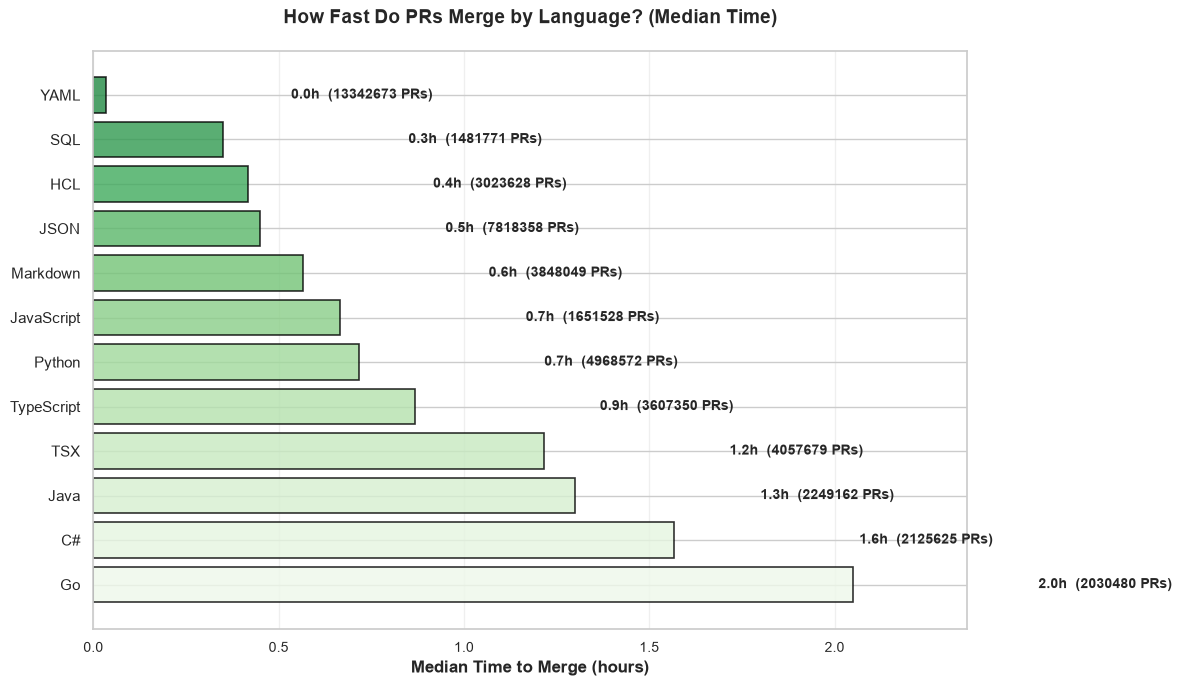

In [11]:
# Plot 7: Merge Time by Language - Clear Bar Chart
import ast

if "primary_language" not in df.columns and "languages_list" in df.columns:
    def parse_languages(value):
        if isinstance(value, list):
            return value
        if isinstance(value, str):
            try:
                parsed = ast.literal_eval(value)
            except (ValueError, SyntaxError):
                return []
            return parsed if isinstance(parsed, list) else []
        return []

    df["languages_list"] = df["languages_list"].apply(parse_languages)
    df["primary_language"] = df["languages_list"].apply(
        lambda x: x[0] if len(x) > 0 else None
    )

if "primary_language" not in df.columns:
    print("No primary_language column could be derived. Available columns:", df.columns.tolist())
elif "minutes_to_merge" not in df.columns:
    print("No minutes_to_merge column found. Available columns:", df.columns.tolist())
else:
    top_langs_count = df["primary_language"].dropna().value_counts().head(12).index
    merge_time_data = df[df["primary_language"].isin(top_langs_count)].copy()
    merge_time_data["minutes_to_merge_hours"] = pd.to_numeric(
        merge_time_data["minutes_to_merge"],
        errors="coerce"
    ) / 60
    merge_time_data = merge_time_data.dropna(subset=["minutes_to_merge_hours"])

    lang_median_merge = (
        merge_time_data
        .groupby("primary_language")["minutes_to_merge_hours"]
        .agg(["median", "mean", "count"])
        .sort_values("median", ascending=False)
    )

    fig, ax = plt.subplots(figsize=(12, 7))

    x_pos = range(len(lang_median_merge))
    colors_gradient = sns.color_palette("RdYlGn_r", len(lang_median_merge))[::-1]
    bars = ax.barh(
        x_pos,
        lang_median_merge["median"],
        color=sns.color_palette("Greens", len(top_langs)),
        edgecolor="black",
        linewidth=1.2,
        alpha=0.8
    )

    ax.set_yticks(x_pos)
    ax.set_yticklabels(lang_median_merge.index, fontsize=11)
    ax.set_xlabel("Median Time to Merge (hours)", fontsize=12, fontweight="bold")
    ax.set_title("How Fast Do PRs Merge by Language? (Median Time)", fontsize=14, fontweight="bold", pad=20)

    for i, (bar, median, count) in enumerate(
        zip(bars, lang_median_merge["median"], lang_median_merge["count"])
    ):
        ax.text(
            median + 0.5,
            i,
            f"{median:.1f}h  ({int(count)} PRs)",
            va="center",
            fontsize=10,
            fontweight="bold"
        )

    ax.tick_params(axis="x", labelsize=10)
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)
    ax.set_xlim(0, lang_median_merge["median"].max() * 1.15)

    plt.tight_layout()
    plt.savefig("dataset_plots/07_merge_time_by_language_median.png", dpi=300, bbox_inches="tight")
    plt.show()

### 7. Pearson correlation matrix

Pearson correlation measures the strength and direction of a linear relationship between two variables. In this analysis, it helps show whether one PR feature tends to increase or decrease as another feature increases. For example, if larger PRs usually took longer to merge, we would expect a positive correlation between lines changed and minutes to merge.

Overall, these results show that PR complexity is not a one-feature problem. No single metric fully explains how complex or difficult a PR is to review. Instead, PR complexity likely depends on a combination of factors, including lines changed, files touched, review activity, comments, reviewers, and time to merge. This supports using a multi-feature complexity score rather than relying on one variable alone.


In [12]:
feature_candidates = [
    "files_added",
    "files_deleted",
    "files_modified",
    "lines_added",
    "lines_modified",
    "code_lines_modified",
    "lines_deleted",
    "num_review_comments",
    "num_reviewers",
    "minutes_to_merge"
]

features = []
for feature in feature_candidates:
    if feature in df.columns and feature not in features:
        features.append(feature)

missing_features = [feature for feature in feature_candidates if feature not in df.columns]
print(f"Correlation features used: {features}")
if missing_features:
    print(f"Features not found and skipped: {missing_features}")

numeric_features = df[features].apply(pd.to_numeric, errors="coerce")
numeric_features = numeric_features.dropna(axis=1, how="all")

pearson_corr = numeric_features.corr(method="pearson")

pearson_corr.round(2)

Correlation features used: ['files_added', 'files_deleted', 'files_modified', 'lines_modified', 'code_lines_modified', 'num_review_comments', 'num_reviewers', 'minutes_to_merge']
Features not found and skipped: ['lines_added', 'lines_deleted']


,files_added,files_deleted,files_modified,lines_modified,code_lines_modified,num_review_comments,num_reviewers,minutes_to_merge
files_added,1.00,0.08,0.64,0.65,0.54,0.10,0.02,0.03
files_deleted,0.08,1.00,0.39,0.34,0.27,0.01,-0.00,0.01
files_modified,0.64,0.39,1.00,0.71,0.62,0.12,0.06,0.04
lines_modified,0.65,0.34,0.71,1.00,0.89,0.15,0.05,0.05
code_lines_modified,0.54,0.27,0.62,0.89,1.00,0.17,0.07,0.05
num_review_comments,0.10,0.01,0.12,0.15,0.17,1.00,0.40,0.15
num_reviewers,0.02,-0.00,0.06,0.05,0.07,0.40,1.00,0.16
minutes_to_merge,0.03,0.01,0.04,0.05,0.05,0.15,0.16,1.00


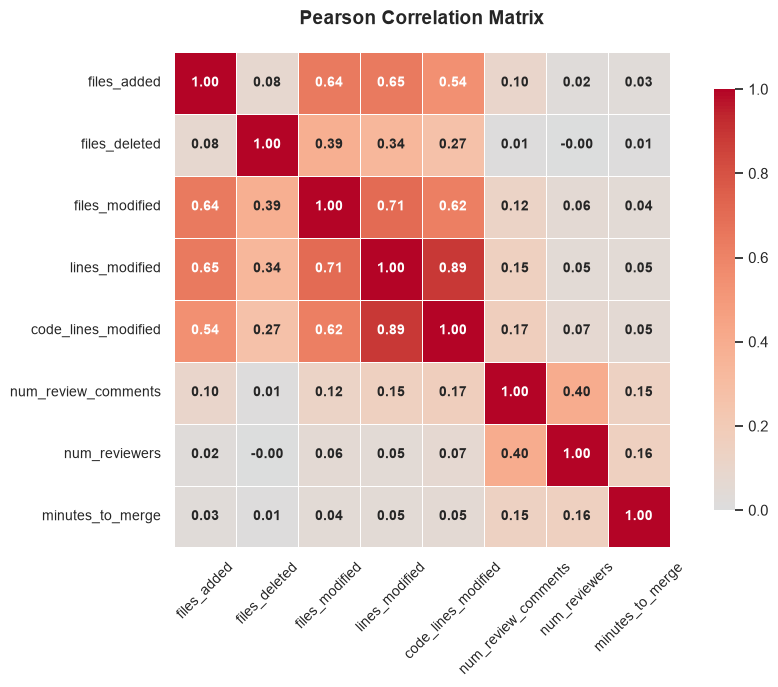

: 

In [ ]:
fig, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.6,
    linecolor="white",
    square=True,
    annot_kws={"fontsize": 10, "fontweight": "bold"},
    cbar_kws={"shrink": 0.85},
    ax=ax
)

ax.set_title("Pearson Correlation Matrix", fontsize=14, fontweight="bold", pad=20)
ax.tick_params(axis="x", labelsize=10, rotation=45)
ax.tick_params(axis="y", labelsize=10, rotation=0)
plt.tight_layout()
plt.show()